# 蒙古水氣來源 — 疊圖用資料與重現

這本 notebook 把簡報裡兩張圖的**底層格點資料**畫回來，並示範怎麼拿去疊圖。

- `tags_preview.png` — 沙漠化比例、三區劃分
- `source_maps.png` — 四個區的水氣來源密度（含／不含等值線）

所有數字都來自同一個檔案 `data/mongolia_overlay.nc`，不需要原始的 425 GB 追蹤輸出，
也不需要我們的程式庫。

**需要的套件**：`numpy` `matplotlib` `xarray` `netcdf4`；
另外兩個可有可無：`regionmask`（畫全球國界）、`rasterio`（轉 GeoTIFF）。

```bash
pip install numpy matplotlib xarray netcdf4 regionmask rasterio
jupyter lab
```

## 0 · 讀檔與共用函式

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

NC = "../data/mongolia_overlay.nc"          # 若把 notebook 移走，改這裡
ds = xr.open_dataset(NC)
lat = ds["latitude"].values                  # 由北到南遞減
lon = ds["longitude"].values
area = ds["cell_area"].values
zones = [str(z) for z in ds["zone"].values]

def zi(name):
    """區名 -> 索引（MN_ALL / DES / FRONT / NON）"""
    return zones.index(name)

def draw_borders(ax, mongolia_only=False):
    """海岸線與國界。全球界線來自 regionmask（第一次會上網抓 Natural Earth，
    抓不到就只畫蒙古國界，圖仍然正確，只是少了底圖）。"""
    if not mongolia_only:
        try:
            import regionmask
            regionmask.defined_regions.natural_earth_v5_0_0.countries_50.plot_regions(
                ax=ax, add_label=False, line_kws=dict(color="0.35", lw=0.35))
        except Exception as e:
            print("（沒有畫全球國界：", type(e).__name__, "— 只畫蒙古）")
    try:
        import json as _j
        with open("../data/mongolia_border.geojson") as f:
            gj = _j.load(f)
        for feat in gj["features"]:
            g = feat["geometry"]
            polys = g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]
            for poly in polys:
                for ring in poly:
                    r = np.asarray(ring)
                    ax.plot(r[:, 0], r[:, 1], color="#1E6091", lw=0.9, zorder=5)
    except Exception as e:
        print("（沒有畫蒙古國界：", type(e).__name__, "）")

def map_axes(ax, extent=None, step=(30, 15)):
    if extent:
        ax.set_xlim(extent[0], extent[1]); ax.set_ylim(extent[2], extent[3])
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    ax.set_xticks(np.arange(np.ceil(x0/step[0])*step[0], x1+1, step[0]))
    ax.set_yticks(np.arange(np.ceil(y0/step[1])*step[1], y1+1, step[1]))
    ax.grid(alpha=0.25, lw=0.4, color="0.5", ls=":")
    ax.set_aspect("equal")
    ax.set_xlabel("longitude"); ax.set_ylabel("latitude")

print("變數：", list(ds.data_vars))
print("區：", zones, "| 網格：", len(lat), "x", len(lon))


變數： ['e_track', 'e_track_per_year', 'source_cdf', 'cell_area', 'des_fraction', 'zone_id']
區： ['MN_ALL', 'DES', 'FRONT', 'NON'] | 網格： 519 x 1440


## 1 · density 是什麼

`e_track` 的單位是 **kg m⁻²** —— 每平方公尺幾公斤水。
這是**密度**，不是總量，也不是比例。

意思是：某一格的值 = 這一格每平方公尺蒸發出去、最後下在蒙古的水有多少公斤。
要得到那一格實際送出多少水（公斤），必須**乘上那一格的面積**。

在 0.25° 的經緯度網格上，格子面積隨 cos(緯度) 變化，高緯度的格子小很多，
所以**任何空間加總都必須先乘面積**。下面這段把差距算給你看。

In [2]:
k = zi("MN_ALL")
dens = ds["e_track"].values[k]                 # kg m-2，36 年總量

naive = np.nansum(dens)                        # 直接加總 —— 錯的
mass  = np.nansum(dens * area)                 # 乘上格面積 —— 對的

print(f"不加權直接加總   {naive:.4g}     (kg m-2 加起來，沒有物理意義)")
print(f"乘上格面積後     {mass:.4g} kg = {mass/1e12:.1f} Gt")
print()
print("為什麼不能直接加：同樣 0.25 度的格子，面積隨緯度變化")
for la in (0, 30, 50, 79.5):
    j = int(np.argmin(np.abs(lat - la)))
    print(f"  緯度 {lat[j]:6.2f}  格面積 {area[j,0]/1e6:8.1f} km2")
j0 = int(np.argmin(np.abs(lat - 0))); j1 = int(np.argmin(np.abs(lat - 79.5)))
print(f"  -> 79.5N 的格子只有赤道的 {area[j1,0]/area[j0,0]:.2f} 倍大")


不加權直接加總   2.939e+07     (kg m-2 加起來，沒有物理意義)
乘上格面積後     1.467e+16 kg = 14674.2 Gt

為什麼不能直接加：同樣 0.25 度的格子，面積隨緯度變化
  緯度   0.00  格面積    772.8 km2
  緯度  30.00  格面積    669.2 km2
  緯度  50.00  格面積    496.7 km2
  緯度  79.50  格面積    140.8 km2
  -> 79.5N 的格子只有赤道的 0.18 倍大


## 2 · 等值線是怎麼來的（累積來源）

圖上的 50 / 90 / 99 % 線**不是**密度的等值線。它們是「累積來源」等值線：

1. 把所有格子依**密度**由大到小排序
2. 依這個順序累加**質量**（密度 × 面積）
3. 除以總質量 → 每一格得到一個百分比

所以 50 % 線圈住的是「**供應該區一半水氣所需的最小面積**」。
先排密度、再加質量，這個配對是重點 —— 這才讓答案是「最小面積」。

這個欄位已經算好存在 `source_cdf` 裡，所以要畫哪個門檻、或一條都不畫，都由你決定。
下面重算一次跟檔案內的對一下，確認算法。

In [3]:
def source_cdf_mass(mass, dens):
    """每一格 -> 「所有密度不低於它的格子，合起來供應了全區水氣的百分之幾」。

    兩個關鍵，順序不能換：
      1. 用「密度」排序（由大到小）
      2. 累加的卻是「質量」(= 密度 x 面積)
    這樣得到的 50% 等值線，圈住的才是「供應一半水氣所需的最小面積」。
    若改用質量排序，答案會變成另一個問題（而且沒什麼用）。

    累加一定要用 float64。float32 會在尾巴失真 —— 而尾巴正是面積的大宗。
    """
    fm = np.asarray(mass, dtype="float64").ravel()
    fd = np.asarray(dens, dtype="float64").ravel()
    out = np.full(fm.shape, np.nan)
    pos = fm > 0
    if pos.any():
        idx = np.where(pos)[0]
        o = idx[np.argsort(fd[idx])[::-1]]       # 依密度排序
        out[o] = np.cumsum(fm[o]) / fm[idx].sum() * 100.0   # 累加質量
    return out.reshape(np.asarray(mass).shape)

# 自己算一次，跟檔案裡存的比對 —— 算法對不對，看這個數字
k = zi("FRONT")
dens = ds["e_track"].values[k]
mine = source_cdf_mass(dens * area, dens)
stored = ds["source_cdf"].values[k]
both = np.isfinite(mine) & np.isfinite(stored)
d = np.abs(mine[both] - stored[both]).max()
print(f"自行重算 vs 檔案內：最大差 {d:.2e} 個百分點（滿刻度 100）")
print(f"NaN 的位置完全一致：{(np.isnan(mine)==np.isnan(stored)).all()}")
print()
print("差值不是 0，原因不是算法不同：檔案裡的 e_track 以 float32 儲存，")
print("而存檔時的 source_cdf 是用 float64 的原始總和算的。密度幾乎相等的格子")
print("在兩者下排序可能互換，於是累積值差了一點點。")
print(f"量級：{d:.1e} 個百分點。50 % 或 90 % 等值線的位置不受影響。")


自行重算 vs 檔案內：最大差 2.44e-03 個百分點（滿刻度 100）
NaN 的位置完全一致：True

差值不是 0，原因不是算法不同：檔案裡的 e_track 以 float32 儲存，
而存檔時的 source_cdf 是用 float64 的原始總和算的。密度幾乎相等的格子
在兩者下排序可能互換，於是累積值差了一點點。
量級：2.4e-03 個百分點。50 % 或 90 % 等值線的位置不受影響。


## 3 · 圖一：沙漠化比例與三區劃分

左 = 每格沙漠化比例（2021–2025 的 500 m 兩類分類，逐格面積平均）。
右 = 由它切出的三個互斥區：比例 ≥ 0.75 為 DES、0.25–0.75 為 FRONT、≤ 0.25 為 NON。

**注意**：沙漠化比例只有 2021–2025 這一個快照，是**終點分類**，不是逐年變化。

三區格數： {'DES': 1822, 'FRONT': 465, 'NON': 658} | 合計 2945


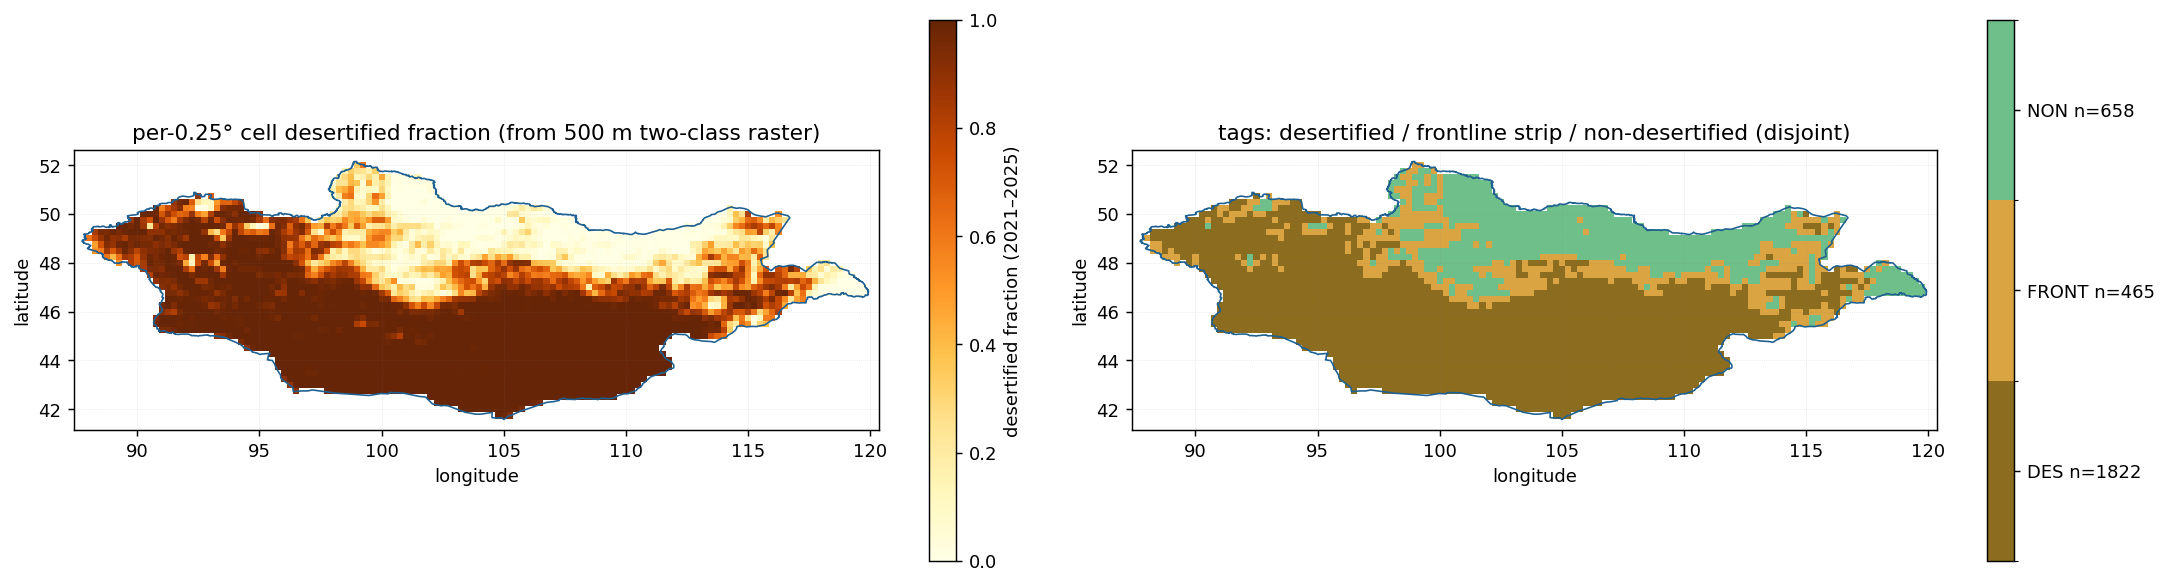

In [4]:
frac = ds["des_fraction"].values
zid  = ds["zone_id"].values
m = np.isfinite(frac) & (zid > 0)              # 蒙古境內
jj, ii = np.where(m)
ext = (lon[ii.min()]-0.6, lon[ii.max()]+0.6, lat[jj.max()]-0.6, lat[jj.min()]+0.6)

fig, axes = plt.subplots(1, 2, figsize=(17, 5.2), dpi=130)

ax = axes[0]
pm = ax.pcolormesh(lon, lat, np.where(m, frac, np.nan), cmap="YlOrBr",
                   vmin=0, vmax=1, shading="auto")
draw_borders(ax, mongolia_only=True)
map_axes(ax, extent=ext, step=(5, 2))
ax.set_title("per-0.25° cell desertified fraction (from 500 m two-class raster)")
plt.colorbar(pm, ax=ax, shrink=0.85, label="desertified fraction (2021–2025)")

ax = axes[1]
from matplotlib.colors import ListedColormap, BoundaryNorm
cmap = ListedColormap(["#8C6D1F", "#D9A441", "#6FBF8B"])      # DES / FRONT / NON
pm = ax.pcolormesh(lon, lat, np.where(zid > 0, zid, np.nan), cmap=cmap,
                   norm=BoundaryNorm([0.5, 1.5, 2.5, 3.5], 3), shading="auto")
draw_borders(ax, mongolia_only=True)
map_axes(ax, extent=ext, step=(5, 2))
n = {z: int((zid == i).sum()) for z, i in (("DES", 1), ("FRONT", 2), ("NON", 3))}
ax.set_title("tags: desertified / frontline strip / non-desertified (disjoint)")
cb = plt.colorbar(pm, ax=ax, shrink=0.85, ticks=[1, 2, 3])
cb.ax.set_yticklabels([f"DES n={n['DES']}", f"FRONT n={n['FRONT']}", f"NON n={n['NON']}"])

fig.tight_layout()
fig.savefig("../figures/tags_preview_repro.png", bbox_inches="tight")
print("三區格數：", n, "| 合計", sum(n.values()))


## 4 · 圖二：四個區的水氣來源

顏色 = 來源密度（log10 kg m⁻²，1990–2025 共 36 年的總量）。
顏色越深 = 那裡蒸發的水，最後下在該區的越多。

把 `SHOW_CONTOURS` 改成 `False` 就沒有等值線；`LEVELS` 可以改成任何門檻。

/tmp/ipykernel_490842/4113143336.py:22: UserWarning: `land_50` of `natural_earth_v4_1_0` and `natural_earth_v5_0_0` does not quite extend to 90°S - it's recommended to use `natural_earth_v5_1_2` instead. See https://github.com/regionmask/regionmask/issues/487
  regionmask.defined_regions.natural_earth_v5_0_0.countries_50.plot_regions(


已存 ../figures/source_maps_repro.png


已存 ../figures/source_maps_repro_nocontour.png


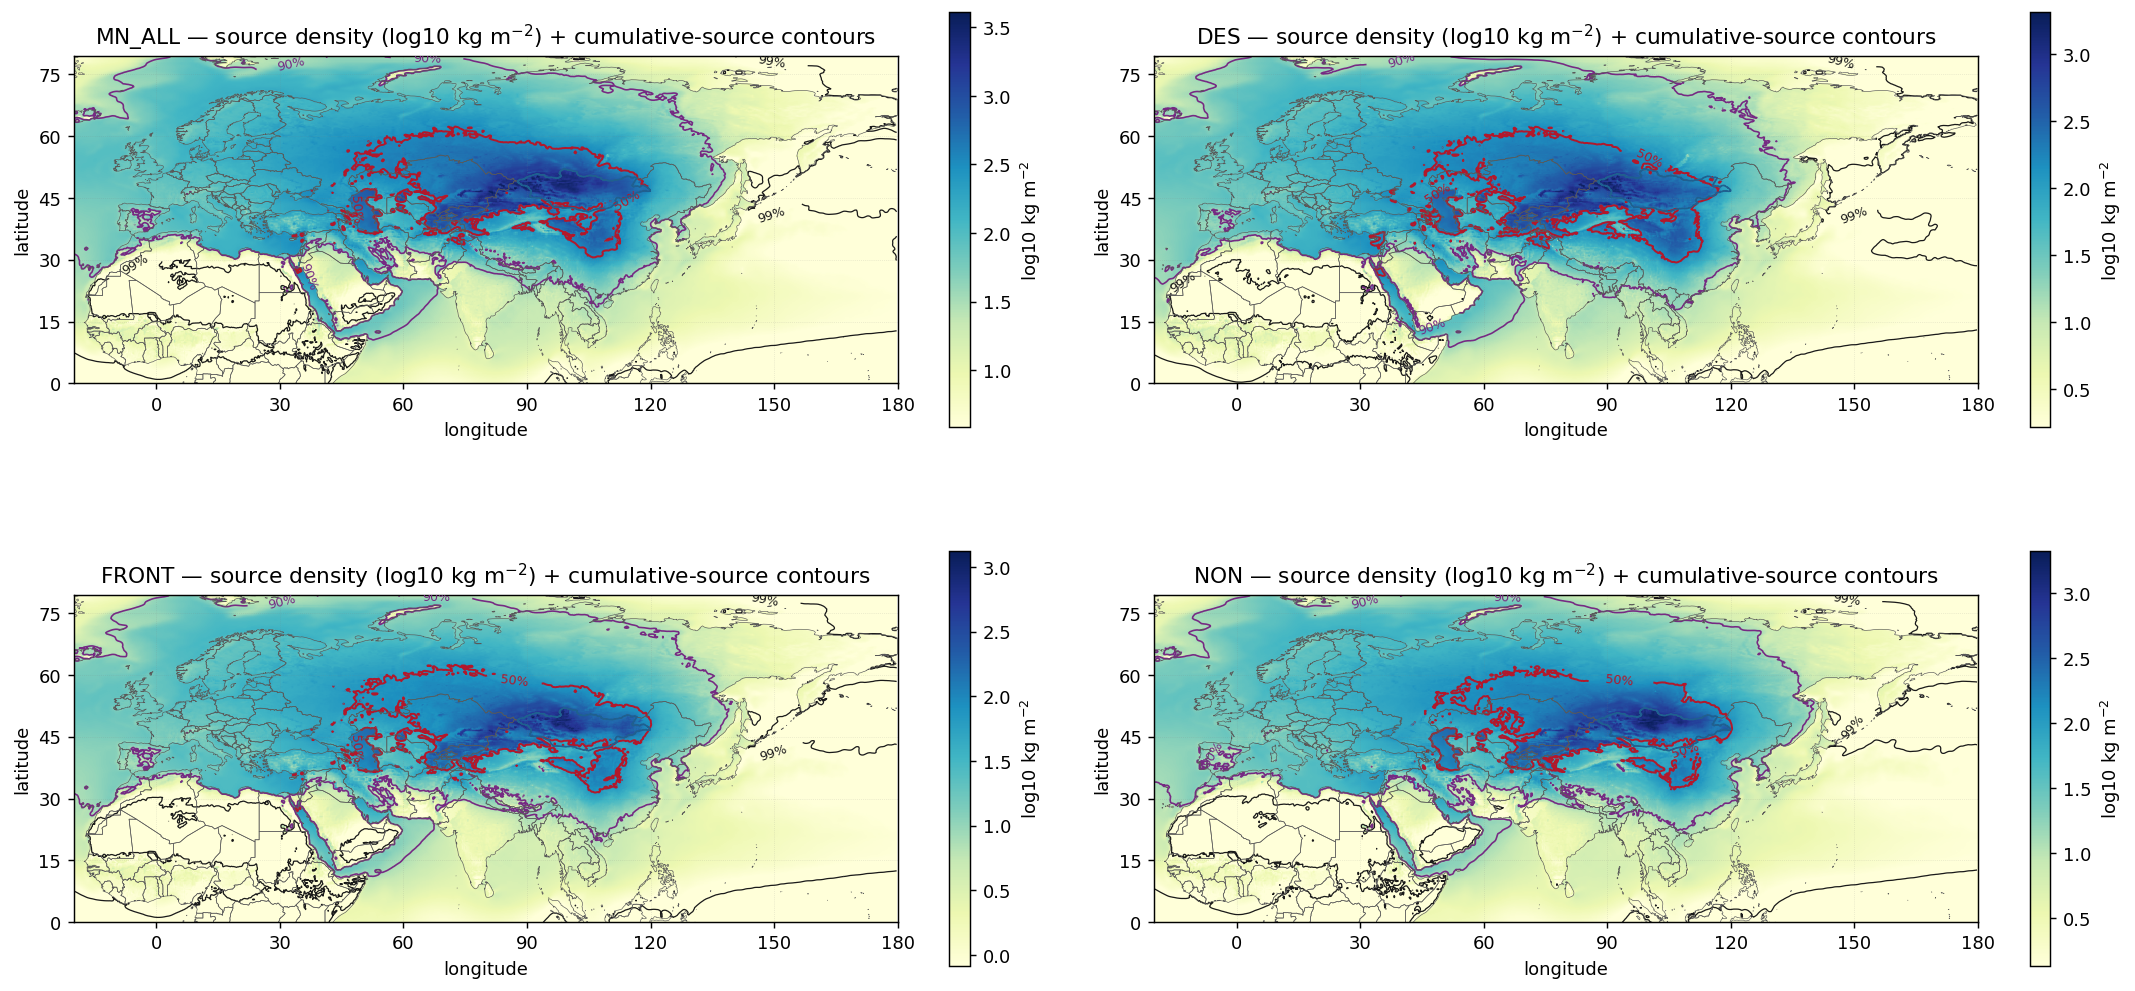

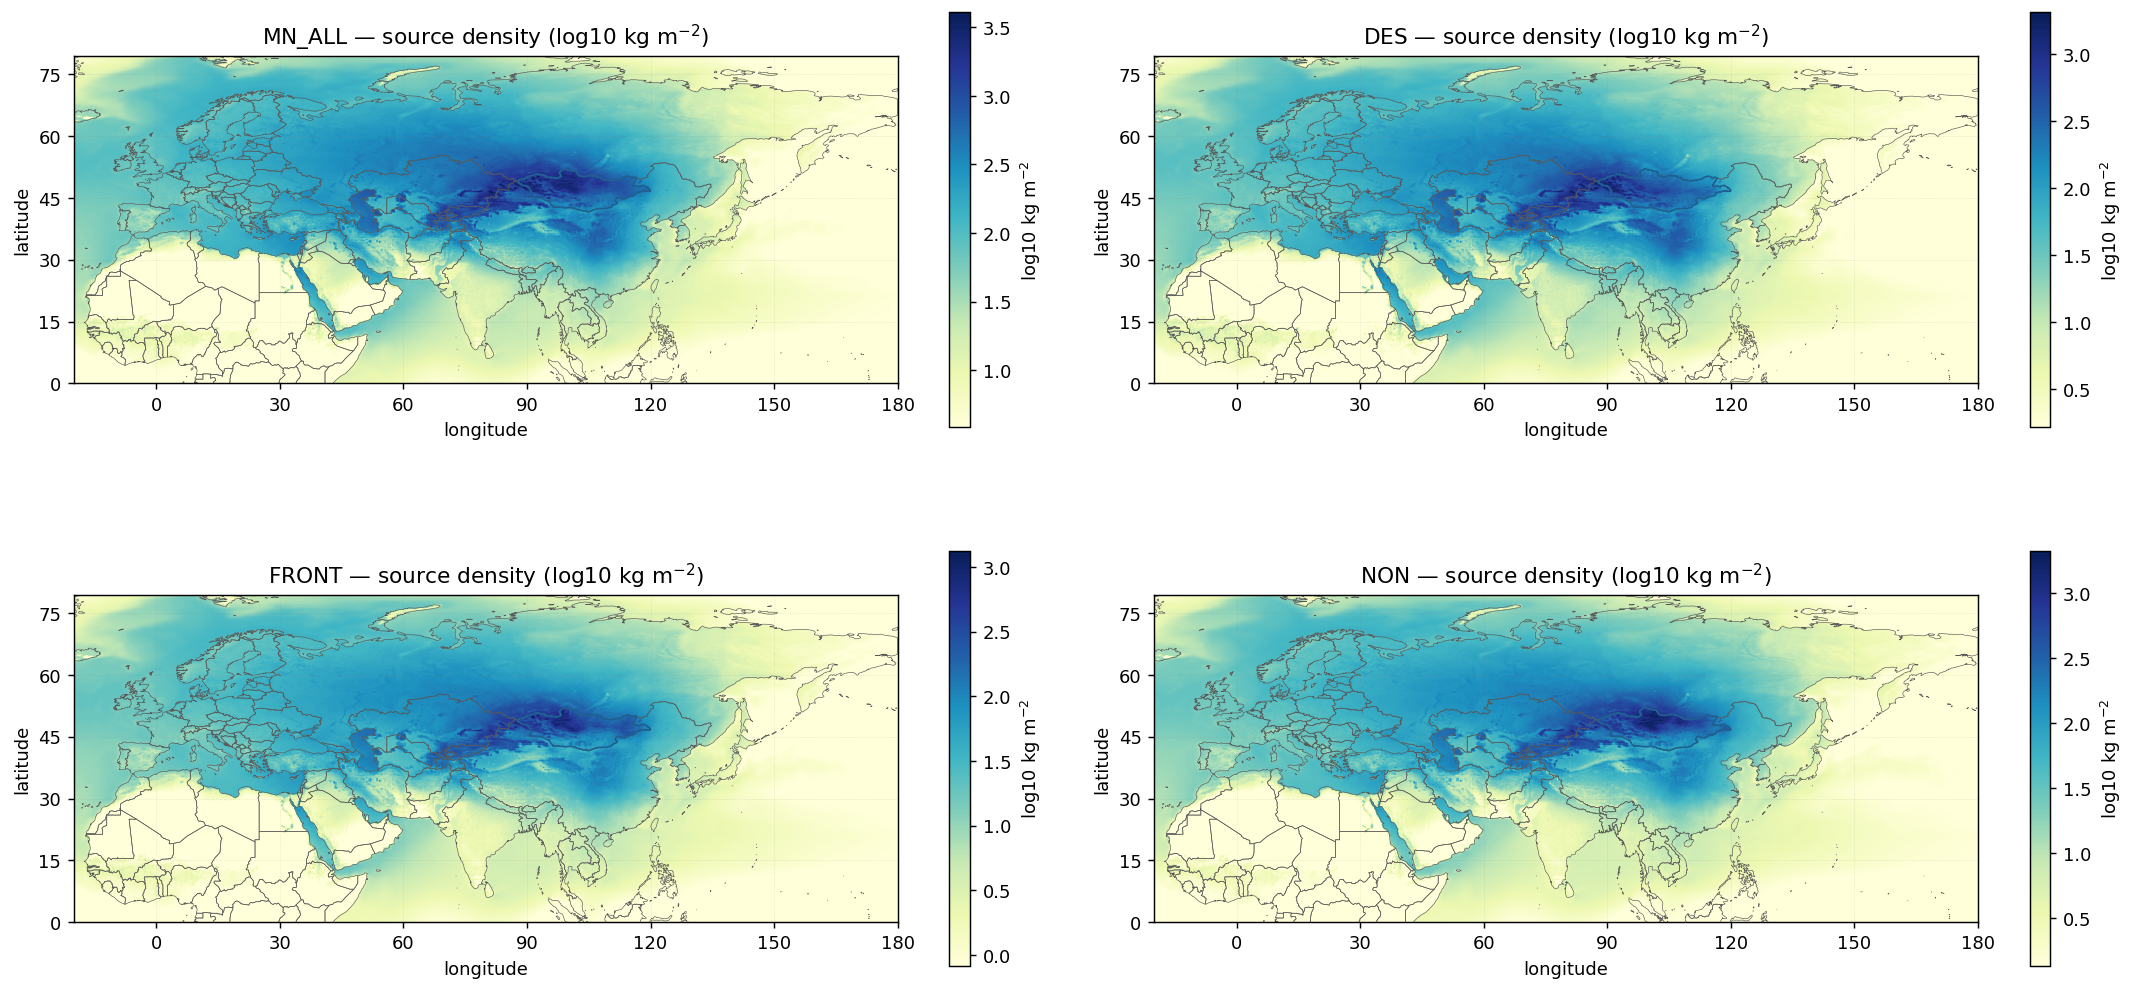

In [5]:
LEVELS = [50, 90, 99]         # <<< 想畫別的門檻就改這裡，例如 [80]
EXTENT = (-20, 180, 0, 79.5)

# 兩個版本都畫出來；自己用的時候把下面這行改成 [True] 或 [False] 即可
for SHOW_CONTOURS in (True, False):
  fig, axes = plt.subplots(2, 2, figsize=(17, 9), dpi=130)
  for ax, z in zip(axes.ravel(), zones):
      k = zi(z)
      dens = ds["e_track"].values[k]
      pos = dens > 0
      pm = ax.pcolormesh(lon, lat, np.log10(np.where(pos, dens, np.nan)),
                         cmap="YlGnBu", shading="auto",
                         vmin=np.log10(np.percentile(dens[pos], 60)),
                         vmax=np.log10(dens[pos].max()))
      if SHOW_CONTOURS:
          cs = ax.contour(lon, lat, ds["source_cdf"].values[k], levels=LEVELS,
                          colors=["#b2182b", "#762a83", "#1a1a1a"][:len(LEVELS)],
                          linewidths=[1.1, 0.9, 0.7][:len(LEVELS)])
          ax.clabel(cs, fmt={l: f"{l}%" for l in LEVELS}, fontsize=7, inline=True)
      draw_borders(ax)
      map_axes(ax, extent=EXTENT)
      ax.set_title(f"{z} — source density (log10 kg m$^{{-2}}$)"
                   + (" + cumulative-source contours" if SHOW_CONTOURS else ""))
      plt.colorbar(pm, ax=ax, shrink=0.7, label="log10 kg m$^{-2}$")

  fig.tight_layout()
  fig.savefig(f"../figures/source_maps_repro{'' if SHOW_CONTOURS else '_nocontour'}.png",
              bbox_inches="tight")
  print("已存", f"../figures/source_maps_repro{'' if SHOW_CONTOURS else '_nocontour'}.png")


## 5 · FRONT 單張，無等值線

疊圖用的乾淨版本。

已存 ../figures/source_FRONT_nocontour.png


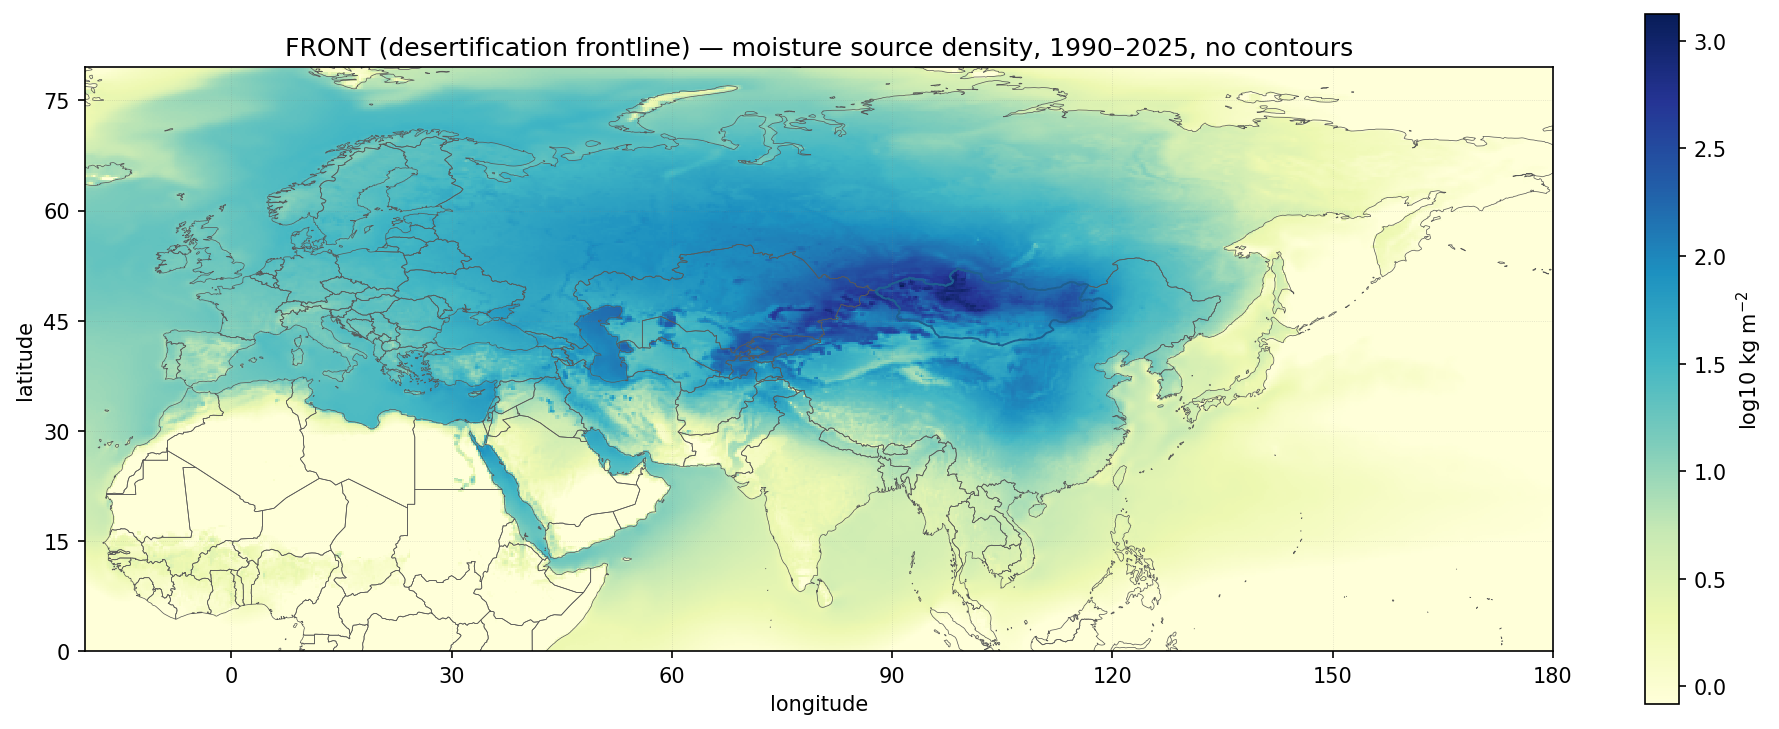

In [6]:
k = zi("FRONT")
dens = ds["e_track"].values[k]
pos = dens > 0

fig, ax = plt.subplots(figsize=(13, 6.2), dpi=150)
pm = ax.pcolormesh(lon, lat, np.log10(np.where(pos, dens, np.nan)),
                   cmap="YlGnBu", shading="auto",
                   vmin=np.log10(np.percentile(dens[pos], 60)),
                   vmax=np.log10(dens[pos].max()))
draw_borders(ax)
map_axes(ax, extent=(-20, 180, 0, 79.5))
ax.set_title("FRONT (desertification frontline) — moisture source density, 1990–2025, no contours")
plt.colorbar(pm, ax=ax, shrink=0.78, label="log10 kg m$^{-2}$")
fig.tight_layout()
fig.savefig("../figures/source_FRONT_nocontour.png", bbox_inches="tight")
print("已存 ../figures/source_FRONT_nocontour.png")


## 6 · 拿去疊圖

`.nc` 本身就是有座標的格點資料（EPSG:4326，0.25°），QGIS 與 xarray 都直接讀。
要轉 GeoTIFF 的話執行下面這格。

**對齊時只有兩件事要注意**：

1. **緯度是遞減的**（由北到南），和 GeoTIFF 的慣例一致，不要再翻一次。
2. 座標是**格中心**。轉 GeoTIFF 時左上角要退半格（`-dlon/2`、`+dlat/2`），
   下面的程式已經處理了。

In [7]:
# 要給 GIS（QGIS / ArcGIS）疊圖時，轉成 GeoTIFF 最省事。
# 需要 rasterio；沒裝就跳過，.nc 本身已經是有座標的格點資料。
try:
    import rasterio
    from rasterio.transform import from_origin

    def to_tif(field, path):
        """lat 是遞減的，GeoTIFF 也要由北到南，所以不必翻轉。"""
        dlat = abs(float(lat[1] - lat[0])); dlon = abs(float(lon[1] - lon[0]))
        tr = from_origin(float(lon[0]) - dlon/2, float(lat[0]) + dlat/2, dlon, dlat)
        with rasterio.open(path, "w", driver="GTiff", height=field.shape[0],
                           width=field.shape[1], count=1, dtype="float32",
                           crs="EPSG:4326", transform=tr, nodata=np.nan,
                           compress="deflate") as d:
            d.write(field.astype("float32"), 1)
        print("寫出", path)

    to_tif(ds["e_track"].values[zi("FRONT")], "../data/FRONT_source_density.tif")
    to_tif(ds["source_cdf"].values[zi("FRONT")], "../data/FRONT_source_cdf.tif")
    to_tif(ds["des_fraction"].values, "../data/des_fraction.tif")
    to_tif(ds["zone_id"].values.astype("float32"), "../data/zone_id.tif")
except ImportError:
    print("沒有 rasterio，略過 GeoTIFF。（.nc 已含座標，xarray/QGIS 都讀得到）")


寫出 ../data/FRONT_source_density.tif
寫出 ../data/FRONT_source_cdf.tif
寫出 ../data/des_fraction.tif
寫出 ../data/zone_id.tif


---

### 檔案裡還有什麼

| 變數 | 內容 |
|---|---|
| `e_track` | 四區來源密度，36 年總量（kg m⁻²）|
| `e_track_per_year` | 同上，除以 36 的年平均 |
| `source_cdf` | 累積來源百分比，等值線就是從這裡畫的 |
| `cell_area` | 每格面積（m²），空間加總必乘 |
| `des_fraction` | 每格沙漠化比例（蒙古境內，其餘 NaN）|
| `zone_id` | 0 非蒙古 / 1 DES / 2 FRONT / 3 NON |

每個變數都有 `description`，用 `ds['e_track'].attrs` 看得到。

另外還有 **465 個前緣網格各自的來源場**（每一格單獨追蹤），那份是 1.4 GB，沒有放進來；需要的話再跟我們說。